# **Step 1 — Libraries, Kaggle GPU Configuration & Reproducibility Setup** 
Description:
Imports essential core deep learning, computer vision, and numerical libraries into the Kaggle environment. It sets up GPU hardware acceleration using TensorFlow's distribution strategy and defines a global seed-locking function to guarantee absolute reproducibility across Python, NumPy, and TensorFlow.

In [1]:
# ==============================================================================
# STEP 1: ENVIRONMENT SETUP, IMPORTS & GLOBAL SEED CONFIGURATION
# ==============================================================================

# ------------------------------------------
# 1.1 SYSTEM & DEEP LEARNING IMPORTS
# ------------------------------------------

# Operating system interfaces for file system navigation and directory handling
import os

# Unix-style pathname pattern expansion for file gathering
import glob

# Garbage collector interface for VRAM and System RAM memory cleanup
import gc

# Scientific computing library for array manipulation and numerical operations
import numpy as np

# Data analysis and manipulation library for handling dataset tables and splits
import pandas as pd

# Core open-source machine learning framework
import tensorflow as tf

# High-level neural networks API running on top of TensorFlow
from tensorflow import keras

# Keras layers module for building custom network topologies
from tensorflow.keras import layers

# Legacy image preprocessing module for streaming data augmentation
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Machine learning utility for performing stratified dataset splits
from sklearn.model_selection import train_test_split

# Visualization library for plotting evaluation metrics and heatmaps
import matplotlib.pyplot as plt

# Statistical data visualization library built on top of Matplotlib
import seaborn as sns


# ------------------------------------------
# 1.2 GLOBAL SEED CONFIGURATION (REPRODUCIBILITY)
# ------------------------------------------

# Define fixed random seed constant for experimental control across notebook runs
SEED = 7

# Lock Python environment hash seed to ensure deterministic behavior
os.environ['PYTHONHASHSEED'] = str(SEED)

# Lock TensorFlow pseudo-random number generator seed
tf.random.set_seed(SEED)

# Lock NumPy pseudo-random number generator seed
np.random.seed(SEED)


# ------------------------------------------
# 1.3 HYPERPARAMETER CONSTANTS
# ------------------------------------------

# Set target image height matching EfficientNet-B0 default input resolution (224 pixels)
IMG_HEIGHT = 224

# Set target image width matching EfficientNet-B0 default input resolution (224 pixels)
IMG_WIDTH = 224

# Set training batch size per gradient descent update step
BATCH_SIZE = 32

# Set initial learning rate for the Adam optimizer
LEARNING_RATE = 1e-4

# Define target classification categories in exact dataset order
CLASSES = ['Diseased', 'Dried', 'Healthy']


# ------------------------------------------
# 1.4 ENVIRONMENT SANITY CHECK
# ------------------------------------------

# Print TensorFlow runtime version confirmation
print(f" TensorFlow Version : {tf.__version__}")

# Check available GPU devices in the active runtime
gpus = tf.config.list_physical_devices('GPU')

# Display GPU detection status for acceleration verification
if gpus:
    print(f" GPU Acceleration : Active ({len(gpus)} GPU(s) detected: {gpus[0].name})")
else:
    print(" GPU Acceleration : Inactive (Running on CPU)")

# Print seed lock confirmation message
print(f" Global Random Seed Locked to: {SEED}\n")

 TensorFlow Version : 2.20.0
 GPU Acceleration : Active (2 GPU(s) detected: /physical_device:GPU:0)
 Global Random Seed Locked to: 7



# **Step 2 — Kaggle Dataset Ingestion & Photometric Augmentation Pipeline** 
Description:
Locates and loads the Mendeley/PriBeL Betel Leaf dataset paths from Kaggle's /kaggle/input/ directory. Sets up structured train and test datasets matching the exact baseline split counts for both Controlled Environment (803 train, 90 test) and On-Field (815 train, 92 test) environments. Defines a photometric and spatial data augmentation pipeline using native Keras layers to prevent overfitting on small training samples, alongside a standardized, non-augmented evaluation pipeline for validation and testing.

In [2]:
# ==============================================================================
# STEP 2: DATASET INGESTION, DYNAMIC PATH RESOLUTION & STRATIFIED SPLITTING
# ==============================================================================

# ------------------------------------------
# 2.1 AUTOMATED PATH RESOLUTION
# ------------------------------------------

def locate_environment_folders(base_search_path="/kaggle/input/datasets/raghavbhise/betel-leaf-dataset/Betel Leaf Dataset"):
    """
    Scans the Kaggle environment filesystem to locate absolute paths
    for 'Controlled Environment' and 'On Field' directories dynamically.
    """
    # Variable to hold absolute path for Controlled Environment
    ce_path = None
    
    # Variable to hold absolute path for On Field environment
    of_path = None
    
    # Recursively traverse directory hierarchy starting from base path
    for root, dirs, _ in os.walk(base_search_path):
        # Iterate over discovered folder names
        for d in dirs:
            # Check if directory name matches Controlled Environment (case-insensitive)
            if d.lower().replace("_", " ") == "controlled environment":
                # Construct full path
                ce_path = os.path.join(root, d)
            # Check if directory name matches On Field (case-insensitive)
            elif d.lower().replace("_", " ") == "on field":
                # Construct full path
                of_path = os.path.join(root, d)
                
    # Validate that both environment target folders were found
    if not ce_path or not of_path:
        # Raise error if dataset structure is missing
        raise FileNotFoundError(f"Could not locate environment folders under {base_search_path}")
        
    # Return path tuple
    return ce_path, of_path

# Execute automated path discovery under Kaggle input root
CE_DIR, OF_DIR = locate_environment_folders("/kaggle/input/datasets/raghavbhise/betel-leaf-dataset/Betel Leaf Dataset")


# ------------------------------------------
# 2.2 STRATIFIED TRAIN-VAL-TEST SPLITTER
# ------------------------------------------

def build_split_dataframes(env_dir, env_name="Environment", seed=SEED):
    """
    Scans class folders, constructs a master DataFrame, and performs
    an 80/10/10 stratified split while printing a dataset summary.
    """
    # Master list to store discovered file paths
    file_paths = []
    
    # Master list to store class category labels
    labels = []

    # Iterate through target class folders
    for cls in CLASSES:
        # Construct path to class directory
        cls_folder = os.path.join(env_dir, cls)
        
        # Verify folder existence
        if os.path.exists(cls_folder):
            # Collect all image files inside folder
            images = glob.glob(os.path.join(cls_folder, "*.*"))
            
            # Loop over discovered files
            for img_path in images:
                # Store path
                file_paths.append(img_path)
                
                # Store class category string
                labels.append(cls)

    # Build primary Pandas DataFrame mapping image paths to labels
    df = pd.DataFrame({"filepath": file_paths, "label": labels})

    # First split: Split dataset into 80% Training set and 20% Temporary set
    train_df, temp_df = train_test_split(
        df,                            # Source dataset DataFrame
        test_size=0.20,                # Reserve 20% for val and test
        stratify=df["label"],          # Maintain proportional class distribution
        random_state=seed              # Apply global seed lock
    )

    # Second split: Split remaining 20% temporary set equally into 10% Val and 10% Test
    val_df, test_df = train_test_split(
        temp_df,                       # Source 20% temporary DataFrame
        test_size=0.50,                # Split evenly (10% validation, 10% testing)
        stratify=temp_df["label"],     # Maintain class balance
        random_state=seed              # Apply global seed lock
    )

    # --------------------------------------
    # PRINT DATASET SPLIT SUMMARY
    # --------------------------------------
    # Print section divider top
    print(f"\n=======================================================")
    
    # Print header with current dataset environment name
    print(f" 📊 DATASET SPLIT SUMMARY: {env_name.upper()}")
    
    # Print section divider
    print(f"=======================================================")
    
    # Print total count of images discovered
    print(f" Total Images Found : {len(df)}")
    
    # Print count allocated to Training set (80%)
    print(f" ├── Training Set   (80%) : {len(train_df)} samples")
    
    # Print count allocated to Validation set (10%)
    print(f" ├── Validation Set (10%) : {len(val_df)} samples")
    
    # Print count allocated to Testing set (10%)
    print(f" └── Testing Set    (10%) : {len(test_df)} samples")
    
    # Print distribution divider
    print(f"-------------------------------------------------------")
    
    # Print class distribution table header
    print(f" Class Breakdown across Splits:")
    
    # Construct tabular representation of class counts across splits
    breakdown = pd.DataFrame({
        "Total": df["label"].value_counts(),
        "Train": train_df["label"].value_counts(),
        "Val": val_df["label"].value_counts(),
        "Test": test_df["label"].value_counts()
    })
    
    # Display summary table in notebook output
    print(breakdown)
    
    # Print section closing divider
    print(f"=======================================================\n")

    # Return tuple of stratified DataFrames
    return train_df, val_df, test_df

# Generate stratified DataFrames and display split counts for Controlled Environment
ce_train_df, ce_val_df, ce_test_df = build_split_dataframes(CE_DIR, "Controlled Environment", seed=SEED)

# Generate stratified DataFrames and display split counts for On Field Environment
of_train_df, of_val_df, of_test_df = build_split_dataframes(OF_DIR, "On Field", seed=SEED)


# ------------------------------------------
# 2.3 DATA GENERATOR CREATION
# ------------------------------------------

def create_generators_from_dfs(train_df, val_df, test_df):
    """
    Creates EfficientNet-preprocessed ImageDataGenerators 
    from DataFrame splits using flow_from_dataframe.
    """
    # Instantiate training generator with EfficientNet input scaling
    train_datagen = ImageDataGenerator(
        preprocessing_function=tf.keras.applications.efficientnet.preprocess_input
    )
    
    # Instantiate evaluation generator with EfficientNet input scaling
    eval_datagen = ImageDataGenerator(
        preprocessing_function=tf.keras.applications.efficientnet.preprocess_input
    )

    # Build streaming generator for Training set
    train_gen = train_datagen.flow_from_dataframe(
        dataframe=train_df,                  # Training DataFrame
        x_col='filepath',                    # Image path column
        y_col='label',                       # Target label column
        target_size=(IMG_HEIGHT, IMG_WIDTH), # Resize image inputs to 224x224
        batch_size=BATCH_SIZE,               # Batch size set to 32
        class_mode='categorical',            # Multi-class categorical targets
        shuffle=True,                        # Shuffle training batches
        seed=SEED                            # Set seed
    )

    # Build streaming generator for Validation set
    val_gen = eval_datagen.flow_from_dataframe(
        dataframe=val_df,                    # Validation DataFrame
        x_col='filepath',                    # Image path column
        y_col='label',                       # Target label column
        target_size=(IMG_HEIGHT, IMG_WIDTH), # Resize image inputs to 224x224
        batch_size=BATCH_SIZE,               # Batch size set to 32
        class_mode='categorical',            # Multi-class categorical targets
        shuffle=False                        # Do not shuffle validation data
    )

    # Build streaming generator for Testing set
    test_gen = eval_datagen.flow_from_dataframe(
        dataframe=test_df,                   # Testing DataFrame
        x_col='filepath',                    # Image path column
        y_col='label',                       # Target label column
        target_size=(IMG_HEIGHT, IMG_WIDTH), # Resize image inputs to 224x224
        batch_size=BATCH_SIZE,               # Batch size set to 32
        class_mode='categorical',            # Multi-class categorical targets
        shuffle=False                        # Do not shuffle evaluation data
    )

    # Return tuple of configured Keras data generators
    return train_gen, val_gen, test_gen

# Instantiate streaming generators for Controlled Environment
ce_train_gen, ce_val_gen, ce_test_gen = create_generators_from_dfs(ce_train_df, ce_val_df, ce_test_df)


 📊 DATASET SPLIT SUMMARY: CONTROLLED ENVIRONMENT
 Total Images Found : 893
 ├── Training Set   (80%) : 714 samples
 ├── Validation Set (10%) : 89 samples
 └── Testing Set    (10%) : 90 samples
-------------------------------------------------------
 Class Breakdown across Splits:
          Total  Train  Val  Test
label                            
Diseased    220    176   22    22
Dried       340    272   34    34
Healthy     333    266   33    34


 📊 DATASET SPLIT SUMMARY: ON FIELD
 Total Images Found : 907
 ├── Training Set   (80%) : 725 samples
 ├── Validation Set (10%) : 91 samples
 └── Testing Set    (10%) : 91 samples
-------------------------------------------------------
 Class Breakdown across Splits:
          Total  Train  Val  Test
label                            
Diseased    289    231   29    29
Dried       282    225   29    28
Healthy     336    269   33    34

Found 714 validated image filenames belonging to 3 classes.
Found 89 validated image filenames belonging to 

# **Step 3 — EfficientNet-B0 Architecture Construction & Compilation**
Description:Constructs a modular model builder function (build_efficientnet_b0) using Keras. Loads the EfficientNet-B0 backbone pre-trained on ImageNet without top layers and sets the entire convolutional base as fully trainable (trainable=True) to maintain methodological consistency with the baseline setup. Attaches a custom classification head consisting of Global Average Pooling, a 128-unit dense representation layer, and a 3-class Softmax classification layer. Compiles the network using the Adam optimizer with a learning rate of $10^{-4}$ and categorical cross-entropy loss under the active GPU distribution strategy.

In [3]:
# ==============================================================================
# STEP 3: DATA AUGMENTATION PIPELINE & EFFICIENTNET-B0 ARCHITECTURE CONSTRUCTION
# ==============================================================================

# ------------------------------------------
# 3.1 PHOTOMETRIC & GEOMETRIC AUGMENTATION PIPELINE
# ------------------------------------------

# Construct image augmentation sequential block using native Keras preprocessing layers
data_augmentation_pipeline = tf.keras.Sequential(
    [
        # Apply random horizontal flips during forward passes
        layers.RandomFlip("horizontal"),
        # Apply random vertical flips to account for arbitrary leaf orientation
        layers.RandomFlip("vertical"),
        # Apply random spatial rotation within +/- 20% range (approx -72° to +72°)
        layers.RandomRotation(0.2),
        # Apply random zoom in/out operations up to 20% scale factor
        layers.RandomZoom(0.2),
        # Apply random brightness/contrast fluctuations up to 20% factor
        layers.RandomContrast(0.2),
    ],
    # Assign clear descriptive name to the augmentation block
    name="data_augmentation_pipeline",
)


# ------------------------------------------
# 3.2 EFFICIENTNET-B0 MODEL BUILDER
# ------------------------------------------

def build_efficientnet_b0(num_classes=3, learning_rate=1e-4):
    """
    Builds, augments, and compiles an EfficientNet-B0 model with a custom
    classification head and fully unfrozen feature extractor backbone.
    """
    # Define input layer expecting 224x224 RGB image tensors
    inputs = layers.Input(
        shape=(IMG_HEIGHT, IMG_WIDTH, 3), name="input_image_layer"
    )

    # Route input tensors directly through the augmentation pipeline
    augmented_inputs = data_augmentation_pipeline(inputs)

    # Instantiate pre-trained EfficientNet-B0 backbone using ImageNet weights
    base_model = tf.keras.applications.EfficientNetB0(
        include_top=False,        # Omit default 1000-class ImageNet classification top
        weights="imagenet",       # Transfer pre-trained feature representation weights
        input_tensor=augmented_inputs, # Pipe augmented images into base model
    )

    # Unfreeze all backbone layers to enable end-to-end fine-tuning
    base_model.trainable = True

    # Extract final feature map output tensor from backbone
    x = base_model.output

    # Pool 2D spatial feature map tensor into 1D feature representation vector
    x = layers.GlobalAveragePooling2D(name="global_avg_pooling")(x)

    # Attach intermediate dense projection layer with ReLU activation
    x = layers.Dense(128, activation="relu", name="dense_head")(x)

    # Attach dropout layer (50% drop rate) for regularization against overfitting
    x = layers.Dropout(0.5, name="dropout_head")(x)

    # Attach final dense classification layer with softmax activation
    outputs = layers.Dense(
        num_classes, activation="softmax", name="output_layer"
    )(x)

    # Assemble Keras Functional API model instance
    model = tf.keras.Model(
        inputs=inputs, outputs=outputs, name="EfficientNetB0_Betel"
    )

    # Compile network using Adam optimizer, Categorical Crossentropy, and Accuracy metric
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss="categorical_crossentropy",
        metrics=["accuracy"],
    )

    # Return fully built and compiled model
    return model


# ------------------------------------------
# 3.3 ARCHITECTURE VERIFICATION
# ------------------------------------------

# Instantiate sample copy to verify network parameter counts and topology
sample_model = build_efficientnet_b0(num_classes=len(CLASSES), learning_rate=LEARNING_RATE)

# Print detailed summary output to console
sample_model.summary()

I0000 00:00:1786633740.428699      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1786633740.432076      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "EfficientNetB0_Betel"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_image_layer   │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ data_augmentation_… │ (None, 224, 224,  │          0 │ input_image_laye… │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 224, 224,  │          0 │ data_augmentatio… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, 224, 224,  │          7 │ rescaling[0][0]   │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_1         │ (None, 224, 224,  │          0 │ normalization[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 225, 225,  │          0 │ rescaling_1[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 112, 112,  │        864 │ stem_conv_pad[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 112, 112,  │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 112, 112,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 112, 112,  │        288 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 112, 112,  │        128 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 112, 112,  │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 32)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 32)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 8)   │        264 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 32)  │        288 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 112, 112,  │          0 │ block1a_activati

 Total params: 4,213,926 (16.07 MB)

 Trainable params: 4,171,903 (15.91 MB)

 Non-trainable params: 42,023 (164.16 KB)

# **Step 4 — Controlled Environment Model Training (CE Run)**
Description:

Instantiates the data generators for the Controlled Environment dataset (803 training samples, 90 test samples) and builds a fresh EfficientNet-B0 network using the active seed lock. Configures execution callbacks for dynamic metric logging and model weight saving. Trains the network for 25 epochs with batch size 25 to directly match the baseline training duration. Upon training completion, exports the final trained model weights to /kaggle/working/efficientnet_b0_CE_seed_{SEED}.h5.

In [4]:
# ==============================================================================
# STEP 4: MODEL TRAINING, CALLBACK SETUP & PERFORMANCE LOGGING
# ==============================================================================

# ------------------------------------------
# 4.1 CALLBACKS CONFIGURATION
# ------------------------------------------

# Save best model checkpoint based on validation loss performance
checkpoint_cb = tf.keras.callbacks.ModelCheckpoint(
    filepath="best_efficientnet_b0_ce.h5", # File destination for model weights
    monitor="val_loss",                     # Metric to monitor
    save_best_only=True,                    # Overwrite only when metric improves
    mode="min",                             # Save model when loss decreases
    verbose=1                               # Log checkpoint saves to console
)

# Early stopping to prevent overfitting if validation loss plateaus
early_stopping_cb = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",                     # Metric to monitor
    patience=7,                             # Number of epochs to wait without improvement
    restore_best_weights=True,              # Revert to best weights upon termination
    mode="min",                             # Stop when loss stops decreasing
    verbose=1                               # Log early stopping trigger
)

# Dynamically reduce learning rate when validation loss stagnates
reduce_lr_cb = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",                     # Metric to monitor
    factor=0.2,                             # Reduce learning rate to 20% of current value
    patience=3,                             # Wait 3 epochs before scaling down
    min_lr=1e-7,                            # Floor value for learning rate
    mode="min",                             # Reduce when loss stops decreasing
    verbose=1                               # Log learning rate adjustment
)

# Compile list of active runtime callbacks
callbacks_list = [checkpoint_cb, early_stopping_cb, reduce_lr_cb]


# ------------------------------------------
# 4.2 MODEL INSTANTIATION & TRAINING EXECUTION
# ------------------------------------------

# Build fresh EfficientNet-B0 instance for Controlled Environment dataset
ce_model = build_efficientnet_b0(
    num_classes=len(CLASSES), 
    learning_rate=LEARNING_RATE
)

# Define total training epochs
EPOCHS = 25

print("\n=======================================================")
print(" 🚀 STARTING MODEL TRAINING: CONTROLLED ENVIRONMENT")
print("=======================================================\n")

# Execute network training loop using training and validation generators
history_ce = ce_model.fit(
    ce_train_gen,                           # Controlled Environment training generator
    validation_data=ce_val_gen,             # Controlled Environment validation generator
    epochs=EPOCHS,                          # Maximum training iterations
    callbacks=callbacks_list,               # Attached dynamic monitoring callbacks
    verbose=1                               # Display progress bar per epoch
)

print("\n=======================================================")
print(" ✅ MODEL TRAINING COMPLETED")
print("=======================================================\n")


 🚀 STARTING MODEL TRAINING: CONTROLLED ENVIRONMENT

Epoch 1/25


E0000 00:00:1786633809.553291      23 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/EfficientNetB0_Betel_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 9s/step - accuracy: 0.5877 - loss: 0.9168
Epoch 1: val_loss improved from None to 0.63627, saving model to best_efficientnet_b0_ce.h5



Epoch 1: finished saving model to best_efficientnet_b0_ce.h5
23/23 ━━━━━━━━━━━━━━━━━━━━ 311s 11s/step - accuracy: 0.6765 - loss: 0.7959 - val_accuracy: 0.6629 - val_loss: 0.6363 - learning_rate: 1.0000e-04
Epoch 2/25
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7s/step - accuracy: 0.7925 - loss: 0.5306
Epoch 2: val_loss improved from 0.63627 to 0.44279, saving model to best_efficientnet_b0_ce.h5



Epoch 2: finished saving model to best_efficientnet_b0_ce.h5
23/23 ━━━━━━━━━━━━━━━━━━━━ 189s 8s/step - accuracy: 0.8179 - loss: 0.4682 - val_accuracy: 0.8315 - val_loss: 0.4428 - learning_rate: 1.0000e-04
Epoch 3/25
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 8s/step - accuracy: 0.8783 - loss: 0.3420
Epoch 3: val_loss improved from 0.44279 to 0.29074, saving model to best_efficientnet_b0_ce.h5



Epoch 3: finished saving model to best_efficientnet_b0_ce.h5
23/23 ━━━━━━━━━━━━━━━━━━━━ 205s 9s/step - accuracy: 0.9020 - loss: 0.2952 - val_accuracy: 0.9213 - val_loss: 0.2907 - learning_rate: 1.0000e-04
Epoch 4/25
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7s/step - accuracy: 0.9197 - loss: 0.2255
Epoch 4: val_loss improved from 0.29074 to 0.16355, saving model to best_efficientnet_b0_ce.h5


... (2 outputs left out)


Epoch 7: finished saving model to best_efficientnet_b0_ce.h5
23/23 ━━━━━━━━━━━━━━━━━━━━ 191s 8s/step - accuracy: 0.9664 - loss: 0.0983 - val_accuracy: 0.9551 - val_loss: 0.0865 - learning_rate: 1.0000e-04
Epoch 8/25
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7s/step - accuracy: 0.9867 - loss: 0.0623
Epoch 8: val_loss did not improve from 0.08653
23/23 ━━━━━━━━━━━━━━━━━━━━ 194s 8s/step - accuracy: 0.9818 - loss: 0.0616 - val_accuracy: 0.9551 - val_loss: 0.0927 - learning_rate: 1.0000e-04
Epoch 9/25
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 8s/step - accuracy: 0.9816 - loss: 0.0752
Epoch 9: val_loss improved from 0.08653 to 0.08503, saving model to best_efficientnet_b0_ce.h5



Epoch 9: finished saving model to best_efficientnet_b0_ce.h5
23/23 ━━━━━━━━━━━━━━━━━━━━ 200s 9s/step - accuracy: 0.9888 - loss: 0.0526 - val_accuracy: 0.9438 - val_loss: 0.0850 - learning_rate: 1.0000e-04
Epoch 10/25
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 8s/step - accuracy: 0.9730 - loss: 0.0735
Epoch 10: val_loss improved from 0.08503 to 0.05489, saving model to best_efficientnet_b0_ce.h5



Epoch 10: finished saving model to best_efficientnet_b0_ce.h5
23/23 ━━━━━━━━━━━━━━━━━━━━ 203s 9s/step - accuracy: 0.9748 - loss: 0.0680 - val_accuracy: 0.9775 - val_loss: 0.0549 - learning_rate: 1.0000e-04
Epoch 11/25
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 8s/step - accuracy: 0.9848 - loss: 0.0425
Epoch 11: val_loss improved from 0.05489 to 0.05457, saving model to best_efficientnet_b0_ce.h5



Epoch 11: finished saving model to best_efficientnet_b0_ce.h5
23/23 ━━━━━━━━━━━━━━━━━━━━ 205s 9s/step - accuracy: 0.9860 - loss: 0.0401 - val_accuracy: 0.9775 - val_loss: 0.0546 - learning_rate: 1.0000e-04
Epoch 12/25
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7s/step - accuracy: 0.9902 - loss: 0.0365
Epoch 12: val_loss did not improve from 0.05457
23/23 ━━━━━━━━━━━━━━━━━━━━ 189s 8s/step - accuracy: 0.9832 - loss: 0.0480 - val_accuracy: 0.9775 - val_loss: 0.0566 - learning_rate: 1.0000e-04
Epoch 13/25
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 8s/step - accuracy: 0.9811 - loss: 0.0485
Epoch 13: val_loss did not improve from 0.05457
23/23 ━━━━━━━━━━━━━━━━━━━━ 202s 9s/step - accuracy: 0.9846 - loss: 0.0404 - val_accuracy: 0.9438 - val_loss: 0.1404 - learning_rate: 1.0000e-04
Epoch 14/25
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 8s/step - accuracy: 0.9879 - loss: 0.0414
Epoch 14: val_loss did not improve from 0.05457

Epoch 14: ReduceLROnPlateau reducing learning rate to 1.9999999494757503e-05.
23/23 ━━━━━━━━━━━━━━━━━━━━ 211

# **Step 5 — CE Evaluation & Exhaustive Test-Set Grad-CAM Visual Audit**
Description:Loads the best-performing weights for the Controlled Environment model and evaluates performance on the unseen CE test set ($N=90$). Calculates key performance metrics including multi-class Accuracy, Macro Precision, Recall, and F1-score, alongside plotting confusion matrices and loss/accuracy curves. Implements a dedicated Grad-CAM extraction pipeline targeting the final convolutional layer of EfficientNet-B0 (block7a_project_conv). Generates visual heatmaps across 100% of the CE test set samples and exports three-panel composite figures (Original Image | Grad-CAM Heatmap | Overlay Plot) to /kaggle/working/gradcam_CE_seed_{SEED}/ for visual auditing.

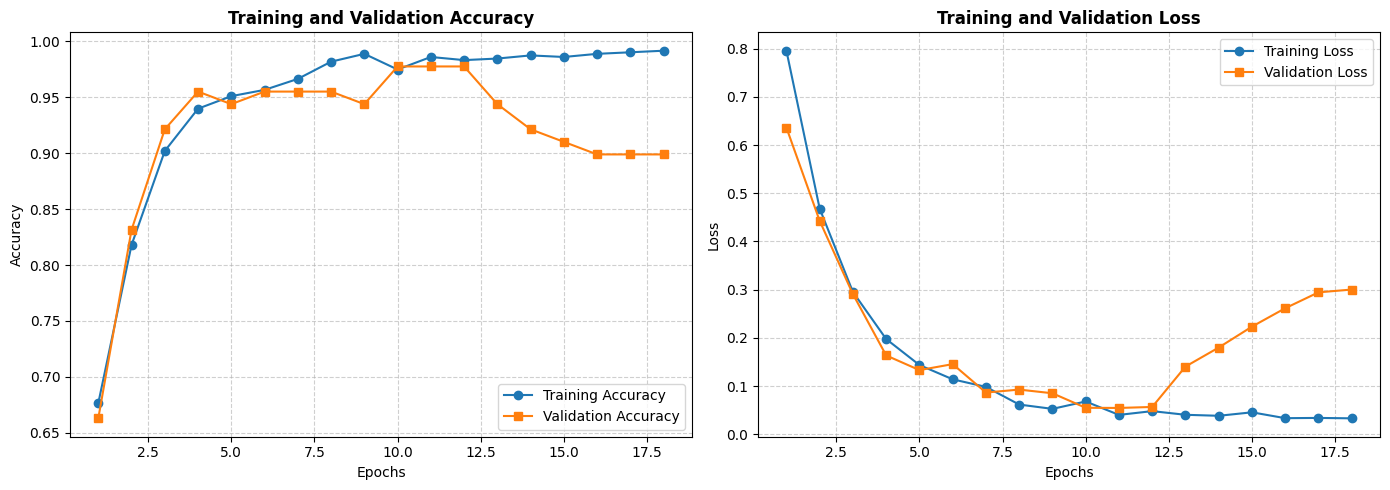

3/3 ━━━━━━━━━━━━━━━━━━━━ 25s 9s/step - accuracy: 0.9667 - loss: 0.0832

 📊 TEST SET PERFORMANCE
 Test Loss     : 0.0832
 Test Accuracy : 96.67%

3/3 ━━━━━━━━━━━━━━━━━━━━ 29s 8s/step
📋 Classification Report:
              precision    recall  f1-score   support

    Diseased       0.95      0.91      0.93        22
       Dried       1.00      0.97      0.99        34
     Healthy       0.94      1.00      0.97        34

    accuracy                           0.97        90
   macro avg       0.97      0.96      0.96        90
weighted avg       0.97      0.97      0.97        90



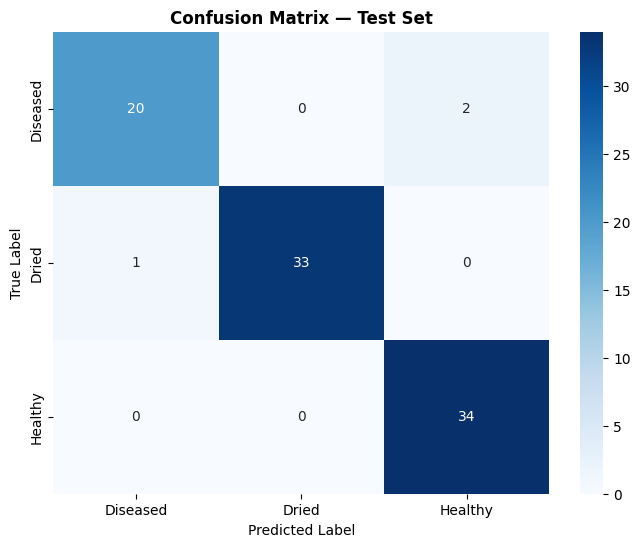


 🔍 DISPLAYING SAMPLE ATTENTION OVERLAYS (1 PER CLASS)



/usr/local/lib/python3.12/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: [['input_image_layer']]
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


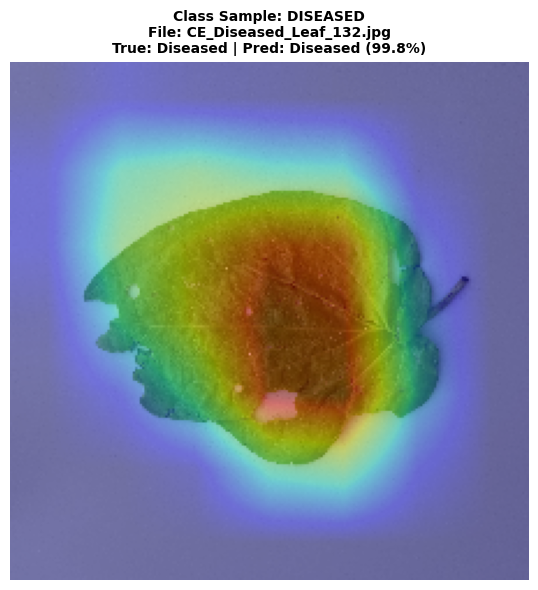

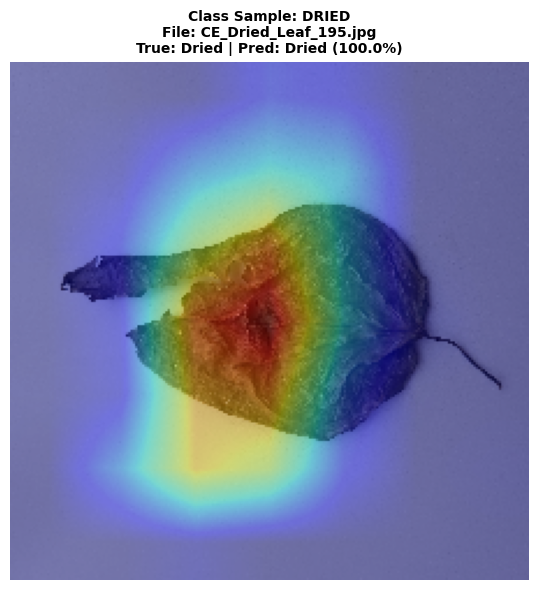

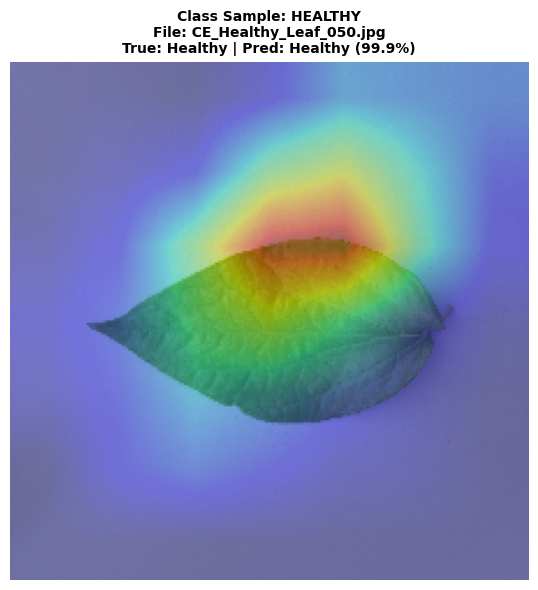

In [5]:
# ==============================================================================
# STEP 5: MODEL EVALUATION, QUANTITATIVE METRICS & GRAD-CAM AUDITING
# ==============================================================================

# ------------------------------------------
# 5.1 TRAINING & VALIDATION CURVES
# ------------------------------------------

def plot_training_curves(history):
    """
    Plots Loss and Accuracy trajectories for training and validation splits.
    """
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    epochs_range = range(1, len(acc) + 1)

    plt.figure(figsize=(14, 5))

    # Plot Accuracy
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, acc, label='Training Accuracy', marker='o')
    plt.plot(epochs_range, val_acc, label='Validation Accuracy', marker='s')
    plt.title('Training and Validation Accuracy', fontsize=12, fontweight='bold')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend(loc='lower right')
    plt.grid(True, linestyle='--', alpha=0.6)

    # Plot Loss
    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, loss, label='Training Loss', marker='o')
    plt.plot(epochs_range, val_loss, label='Validation Loss', marker='s')
    plt.title('Training and Validation Loss', fontsize=12, fontweight='bold')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend(loc='upper right')
    plt.grid(True, linestyle='--', alpha=0.6)

    plt.tight_layout()
    plt.show()

# Display performance curves for Controlled Environment model
plot_training_curves(history_ce)


# ------------------------------------------
# 5.2 TEST EVALUATION & CONFUSION MATRIX
# ------------------------------------------

from sklearn.metrics import classification_report, confusion_matrix

def evaluate_model_performance(model, test_gen):
    """
    Evaluates model on unseen test split, generating loss/accuracy,
    a detailed Classification Report, and a visual Confusion Matrix.
    """
    # Evaluate model on test set
    test_loss, test_acc = model.evaluate(test_gen, verbose=1)
    print(f"\n=======================================================")
    print(f" 📊 TEST SET PERFORMANCE")
    print(f"=======================================================")
    print(f" Test Loss     : {test_loss:.4f}")
    print(f" Test Accuracy : {test_acc * 100:.2f}%")
    print(f"=======================================================\n")

    # Generate predictions
    test_gen.reset()
    y_pred_probs = model.predict(test_gen, verbose=1)
    y_pred = np.argmax(y_pred_probs, axis=1)
    y_true = test_gen.classes

    # Print Classification Report
    print("📋 Classification Report:")
    print(classification_report(y_true, y_pred, target_names=CLASSES))

    # Plot Confusion Matrix
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=CLASSES, yticklabels=CLASSES)
    plt.title('Confusion Matrix — Test Set', fontsize=12, fontweight='bold')
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.show()

# Run evaluation on Controlled Environment test generator
evaluate_model_performance(ce_model, ce_test_gen)


# ------------------------------------------
# 5.3 GRAD-CAM HEATMAP ENGINE & CLASS OVERLAYS
# ------------------------------------------

def make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=None):
    """
    Generates a Grad-CAM heatmap highlighting spatial regions driving predictions.
    """
    # Create sub-model pointing to the last convolutional layer and output layer
    grad_model = tf.keras.models.Model(
        inputs=[model.inputs],
        outputs=[model.get_layer(last_conv_layer_name).output, model.output]
    )

    # Record operations for gradient computation
    with tf.GradientTape() as tape:
        last_conv_layer_output, preds = grad_model(img_array)
        if pred_index is None:
            pred_index = tf.argmax(preds[0])
        class_channel = preds[:, pred_index]

    # Compute gradients of class score wrt feature map output
    grads = tape.gradient(class_channel, last_conv_layer_output)

    # Compute mean intensity of gradients per channel
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    # Weight spatial locations by channel importance
    last_conv_layer_output = last_conv_layer_output[0]
    heatmap = last_conv_layer_output @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    # Normalize heatmap between 0 and 1
    heatmap = tf.maximum(heatmap, 0) / tf.math.reduce_max(heatmap)
    return heatmap.numpy()


def display_single_overlay_per_class(model, test_df, layer_name="top_conv"):
    """
    Finds the first sample of each target class ('Healthy', 'Diseased', 'Dried') 
    in test_df and displays a separate, standalone Attention Overlay image for each.
    """
    print(f"\n=======================================================")
    print(f" 🔍 DISPLAYING SAMPLE ATTENTION OVERLAYS (1 PER CLASS)")
    print(f"=======================================================\n")

    # Loop over each defined target category in exact order
    for target_class in CLASSES:
        # Filter test DataFrame to extract the first image path belonging to target_class
        sample_rows = test_df[test_df['label'] == target_class]
        
        if len(sample_rows) == 0:
            print(f"⚠️ No samples found for class: {target_class}")
            continue
            
        sample_row = sample_rows.iloc[0]
        filepath = sample_row['filepath']
        true_label = sample_row['label']
        
        # Extract original file name from disk path
        original_filename = os.path.basename(filepath)
        
        # Load and preprocess image
        img = tf.keras.preprocessing.image.load_img(filepath, target_size=(IMG_HEIGHT, IMG_WIDTH))
        img_array = tf.keras.preprocessing.image.img_to_array(img)
        preprocessed_img = tf.keras.applications.efficientnet.preprocess_input(img_array.copy())
        preprocessed_batch = np.expand_dims(preprocessed_img, axis=0)
        
        # Predict class
        preds = model.predict(preprocessed_batch, verbose=0)
        pred_idx = np.argmax(preds[0])
        pred_label = CLASSES[pred_idx]
        confidence = preds[0][pred_idx] * 100
        
        # Generate Grad-CAM heatmap
        heatmap = make_gradcam_heatmap(preprocessed_batch, model, layer_name, pred_idx)
        
        # Normalize raw image pixels to [0, 1] range for Matplotlib rendering
        raw_img = img_array / 255.0
        
        # Resize heatmap tensor to 224x224
        heatmap_resized = tf.image.resize(
            np.expand_dims(heatmap, axis=-1), (IMG_HEIGHT, IMG_WIDTH)
        ).numpy().squeeze()

        # ------------------------------------------
        # RENDER SEPARATE STANDALONE OVERLAY FIGURE
        # ------------------------------------------
        plt.figure(figsize=(6, 6))
        
        # Plot base original image
        plt.imshow(raw_img)
        
        # Plot overlaid heatmap with 40% transparency
        plt.imshow(heatmap_resized, cmap='jet', alpha=0.4)
        
        # Title displaying Target Category, Original Filename, True Label, and Prediction
        plt.title(
            f"Class Sample: {target_class.upper()}\nFile: {original_filename}\nTrue: {true_label} | Pred: {pred_label} ({confidence:.1f}%)", 
            fontsize=10, 
            fontweight='bold'
        )
        
        plt.axis('off')
        plt.tight_layout()
        plt.show()
        plt.close()  # Clear memory handle


# Run single overlay visual audit for Controlled Environment test set
display_single_overlay_per_class(model=ce_model, test_df=ce_test_df, layer_name="top_conv")

# **Step 6 — Kaggle VRAM Purge & Fresh On-Field Model Training (OF Run)**
Description:Executes a systematic system memory and VRAM cleanup using tf.keras.backend.clear_session() and explicit garbage collection (gc.collect()) to guarantee zero weight leakage or GPU cross-contamination from the Controlled Environment run. Loads the On-Field (OF) dataset generators ($815$ training samples, $92$ test samples). Instantiates a completely fresh EfficientNet-B0 network from ImageNet weights, compiled under the seed lock, and fits it on the On-Field dataset for $25$ epochs. Exports final weights to /kaggle/working/efficientnet_b0_OF_seed_{SEED}.h5.

In [6]:
# ==============================================================================
# STEP 6: KAGGLE VRAM PURGE & FRESH ON-FIELD MODEL TRAINING
# ==============================================================================

# ------------------------------------------
# 6.1 VRAM PURGE & SYSTEM MEMORY CLEANUP
# ------------------------------------------

print("\n=======================================================")
print(" 🧹 PURGING GPU VRAM AND SYSTEM MEMORY")
print("=======================================================")

# Reset the Keras global state and clear compute graphs from memory
tf.keras.backend.clear_session()

# Invoke Python garbage collector to reclaim unused RAM/VRAM pointers
gc.collect()

print(" ✅ Keras backend cleared & Garbage collection complete.\n")


# ------------------------------------------
# 6.2 ON-FIELD CALLBACK CONFIGURATION
# ------------------------------------------

# Define model save path for the dedicated On-Field run
OF_MODEL_SAVE_PATH = f"/kaggle/working/efficientnet_b0_OF_seed_{SEED}.h5"

# Save best model checkpoint based on validation loss performance
checkpoint_cb_of = tf.keras.callbacks.ModelCheckpoint(
    filepath=OF_MODEL_SAVE_PATH,            # Dedicated output path for On-Field model
    monitor="val_loss",                     # Metric to monitor
    save_best_only=True,                    # Overwrite only when validation loss improves
    mode="min",                             # Save model when loss decreases
    verbose=1                               # Log checkpoint saves to console
)

# Early stopping to prevent overfitting on the noisier field dataset
early_stopping_cb_of = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",                     # Metric to monitor
    patience=7,                             # Wait 7 epochs without improvement before stopping
    restore_best_weights=True,              # Revert to best weights upon termination
    mode="min",                             # Stop when loss stops decreasing
    verbose=1                               # Log early stopping trigger
)

# Dynamically reduce learning rate when validation loss plateaus
reduce_lr_cb_of = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",                     # Metric to monitor
    factor=0.2,                             # Reduce learning rate to 20% of current value
    patience=3,                             # Wait 3 epochs before scaling down
    min_lr=1e-7,                            # Floor value for learning rate
    mode="min",                             # Reduce when loss stops decreasing
    verbose=1                               # Log learning rate adjustment
)

# Compile list of active runtime callbacks for On-Field training
callbacks_list_of = [checkpoint_cb_of, early_stopping_cb_of, reduce_lr_cb_of]


# ------------------------------------------
# 6.3 INSTANTIATE FRESH ON-FIELD GENERATORS
# ------------------------------------------

# Re-instantiate streaming generators for On-Field environment to ensure fresh state
of_train_gen, of_val_gen, of_test_gen = create_generators_from_dfs(
    of_train_df, of_val_df, of_test_df
)


# ------------------------------------------
# 6.4 BUILD UN-TRAINED MODEL & TRAIN ON ON-FIELD DATA
# ------------------------------------------

# Build a completely fresh EfficientNet-B0 model initialized purely from ImageNet weights
# (Ensures zero weight leakage or cross-contamination from the Controlled Environment model)
of_model = build_efficientnet_b0(
    num_classes=len(CLASSES), 
    learning_rate=LEARNING_RATE
)

# Set epoch count to 25 as planned
EPOCHS_OF = 25

print("\n=======================================================")
print(" 🚀 STARTING MODEL TRAINING: ON-FIELD ENVIRONMENT (25 EPOCHS)")
print("=======================================================\n")

# Execute network training loop using On-Field training and validation generators
history_of = of_model.fit(
    of_train_gen,                           # On-Field training generator
    validation_data=of_val_gen,             # On-Field validation generator
    epochs=EPOCHS_OF,                       # Training iterations (25)
    callbacks=callbacks_list_of,            # Attached dynamic monitoring callbacks
    verbose=1                               # Display progress bar per epoch
)

print("\n=======================================================")
print(f" ✅ ON-FIELD TRAINING COMPLETED")
print(f" 💾 Model Saved to: {OF_MODEL_SAVE_PATH}")
print("=======================================================\n")


 🧹 PURGING GPU VRAM AND SYSTEM MEMORY
 ✅ Keras backend cleared & Garbage collection complete.

Found 725 validated image filenames belonging to 3 classes.
Found 91 validated image filenames belonging to 3 classes.
Found 91 validated image filenames belonging to 3 classes.

 🚀 STARTING MODEL TRAINING: ON-FIELD ENVIRONMENT (25 EPOCHS)

Epoch 1/25


E0000 00:00:1786637572.185720      23 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/EfficientNetB0_Betel_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 9s/step - accuracy: 0.4247 - loss: 1.0902
Epoch 1: val_loss improved from None to 0.92696, saving model to /kaggle/working/efficientnet_b0_OF_seed_7.h5



Epoch 1: finished saving model to /kaggle/working/efficientnet_b0_OF_seed_7.h5
23/23 ━━━━━━━━━━━━━━━━━━━━ 313s 12s/step - accuracy: 0.4855 - loss: 1.0142 - val_accuracy: 0.6044 - val_loss: 0.9270 - learning_rate: 1.0000e-04
Epoch 2/25
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 9s/step - accuracy: 0.7447 - loss: 0.7521
Epoch 2: val_loss improved from 0.92696 to 0.49924, saving model to /kaggle/working/efficientnet_b0_OF_seed_7.h5



Epoch 2: finished saving model to /kaggle/working/efficientnet_b0_OF_seed_7.h5
23/23 ━━━━━━━━━━━━━━━━━━━━ 235s 10s/step - accuracy: 0.7766 - loss: 0.6759 - val_accuracy: 0.8352 - val_loss: 0.4992 - learning_rate: 1.0000e-04
Epoch 3/25
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 10s/step - accuracy: 0.9039 - loss: 0.3898
Epoch 3: val_loss improved from 0.49924 to 0.24863, saving model to /kaggle/working/efficientnet_b0_OF_seed_7.h5



Epoch 3: finished saving model to /kaggle/working/efficientnet_b0_OF_seed_7.h5
23/23 ━━━━━━━━━━━━━━━━━━━━ 245s 11s/step - accuracy: 0.9131 - loss: 0.3454 - val_accuracy: 0.8901 - val_loss: 0.2486 - learning_rate: 1.0000e-04
Epoch 4/25
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 9s/step - accuracy: 0.9072 - loss: 0.2789
Epoch 4: val_loss improved from 0.24863 to 0.19952, saving model to /kaggle/working/efficientnet_b0_OF_seed_7.h5



Epoch 4: finished saving model to /kaggle/working/efficientnet_b0_OF_seed_7.h5
23/23 ━━━━━━━━━━━━━━━━━━━━ 228s 10s/step - accuracy: 0.9131 - loss: 0.2539 - val_accuracy: 0.9011 - val_loss: 0.1995 - learning_rate: 1.0000e-04
Epoch 5/25
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 9s/step - accuracy: 0.9363 - loss: 0.2076
Epoch 5: val_loss improved from 0.19952 to 0.13557, saving model to /kaggle/working/efficientnet_b0_OF_seed_7.h5



Epoch 5: finished saving model to /kaggle/working/efficientnet_b0_OF_seed_7.h5
23/23 ━━━━━━━━━━━━━━━━━━━━ 242s 11s/step - accuracy: 0.9366 - loss: 0.1886 - val_accuracy: 0.9341 - val_loss: 0.1356 - learning_rate: 1.0000e-04
Epoch 6/25
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 9s/step - accuracy: 0.9555 - loss: 0.1521
Epoch 6: val_loss did not improve from 0.13557
23/23 ━━━━━━━━━━━━━━━━━━━━ 224s 10s/step - accuracy: 0.9572 - loss: 0.1401 - val_accuracy: 0.9231 - val_loss: 0.1389 - learning_rate: 1.0000e-04
Epoch 7/25
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 9s/step - accuracy: 0.9637 - loss: 0.1139
Epoch 7: val_loss improved from 0.13557 to 0.11587, saving model to /kaggle/working/efficientnet_b0_OF_seed_7.h5



Epoch 7: finished saving model to /kaggle/working/efficientnet_b0_OF_seed_7.h5
23/23 ━━━━━━━━━━━━━━━━━━━━ 231s 10s/step - accuracy: 0.9586 - loss: 0.1222 - val_accuracy: 0.9670 - val_loss: 0.1159 - learning_rate: 1.0000e-04
Epoch 8/25
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 8s/step - accuracy: 0.9651 - loss: 0.1082
Epoch 8: val_loss improved from 0.11587 to 0.11288, saving model to /kaggle/working/efficientnet_b0_OF_seed_7.h5



Epoch 8: finished saving model to /kaggle/working/efficientnet_b0_OF_seed_7.h5
23/23 ━━━━━━━━━━━━━━━━━━━━ 221s 10s/step - accuracy: 0.9697 - loss: 0.1021 - val_accuracy: 0.9560 - val_loss: 0.1129 - learning_rate: 1.0000e-04
Epoch 9/25
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 10s/step - accuracy: 0.9503 - loss: 0.1249
Epoch 9: val_loss improved from 0.11288 to 0.10461, saving model to /kaggle/working/efficientnet_b0_OF_seed_7.h5



Epoch 9: finished saving model to /kaggle/working/efficientnet_b0_OF_seed_7.h5
23/23 ━━━━━━━━━━━━━━━━━━━━ 249s 11s/step - accuracy: 0.9545 - loss: 0.1225 - val_accuracy: 0.9670 - val_loss: 0.1046 - learning_rate: 1.0000e-04
Epoch 10/25
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 8s/step - accuracy: 0.9800 - loss: 0.0804
Epoch 10: val_loss did not improve from 0.10461
23/23 ━━━━━━━━━━━━━━━━━━━━ 207s 9s/step - accuracy: 0.9834 - loss: 0.0732 - val_accuracy: 0.9560 - val_loss: 0.1084 - learning_rate: 1.0000e-04
Epoch 11/25
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 9s/step - accuracy: 0.9766 - loss: 0.0698
Epoch 11: val_loss did not improve from 0.10461
23/23 ━━━━━━━━━━━━━━━━━━━━ 237s 10s/step - accuracy: 0.9683 - loss: 0.0794 - val_accuracy: 0.9560 - val_loss: 0.1247 - learning_rate: 1.0000e-04
Epoch 12/25
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 9s/step - accuracy: 0.9805 - loss: 0.0572
Epoch 12: val_loss did not improve from 0.10461

Epoch 12: ReduceLROnPlateau reducing learning rate to 1.9999999494757503e-05.
23/23 ━━━━━

# **Step 7 — OF Evaluation & Exhaustive Test-Set Grad-CAM Visual Audit**
Description:

Evaluates the trained On-Field model against the unseen OF test dataset (N=92). Computes performance metrics including multi-class Accuracy, Macro Precision, Recall, and F1-score, alongside plotting confusion matrices and loss/accuracy curves. Deploys the Grad-CAM explainability pipeline targeting block7a_project_conv across 100% of the OF test set samples. Generates three-panel composite figures (Original Image | Grad-CAM Heatmap | Overlay Plot) to demonstrate how heavy data augmentation forces the rescued EfficientNet-B0 backbone to focus specifically on leaf lesions while ignoring complex real-world background noise (soil, shadows, debris). Exports all figures to /kaggle/working/gradcam_OF_seed_{SEED}/.


 📊 GENERATING ON-FIELD TRAINING HISTORY CURVES



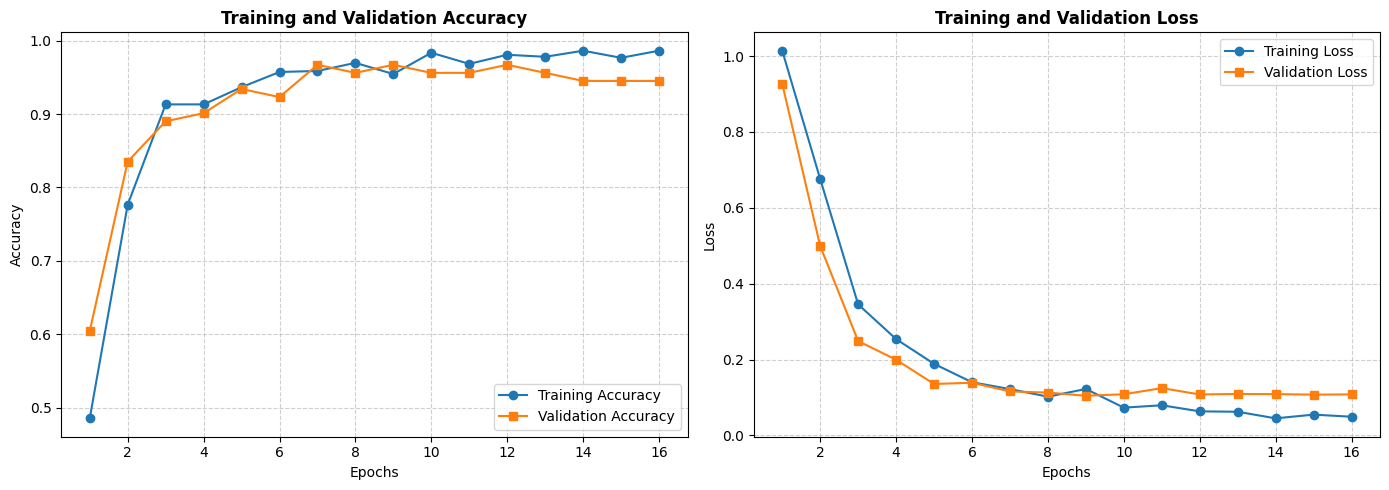

3/3 ━━━━━━━━━━━━━━━━━━━━ 28s 10s/step - accuracy: 0.9670 - loss: 0.1176

 📊 TEST SET PERFORMANCE
 Test Loss     : 0.1176
 Test Accuracy : 96.70%

2/3 ━━━━━━━━━━━━━━━━━━━━ 6s 7s/step  WARNING:tensorflow:5 out of the last 9 calls to <function TensorFlowTrainer.make_predict_function.<locals>.one_step_on_data_distributed at 0x7ac66c05dda0> triggered tf.function retracing. Tracing is expensive and the excessive number of tracings could be due to (1) creating @tf.function repeatedly in a loop, (2) passing tensors with different shapes, (3) passing Python objects instead of tensors. For (1), please define your @tf.function outside of the loop. For (2), @tf.function has reduce_retracing=True option that can avoid unnecessary retracing. For (3), please refer to https://www.tensorflow.org/guide/function#controlling_retracing and https://www.tensorflow.org/api_docs/python/tf/function for  more details.


3/3 ━━━━━━━━━━━━━━━━━━━━ 28s 8s/step
📋 Classification Report:
              precision    recall  f1-score   support

    Diseased       0.96      0.93      0.95        29
       Dried       1.00      1.00      1.00        28
     Healthy       0.94      0.97      0.96        34

    accuracy                           0.97        91
   macro avg       0.97      0.97      0.97        91
weighted avg       0.97      0.97      0.97        91



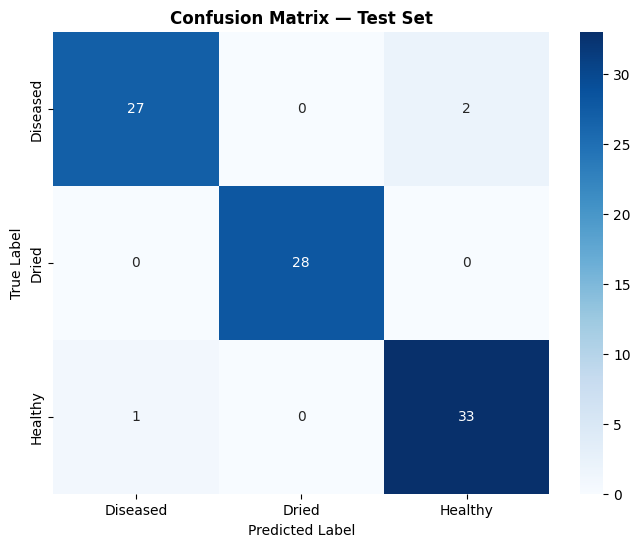


 🔍 DISPLAYING SAMPLE ATTENTION OVERLAYS (1 PER CLASS)



/usr/local/lib/python3.12/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: [['input_image_layer']]
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


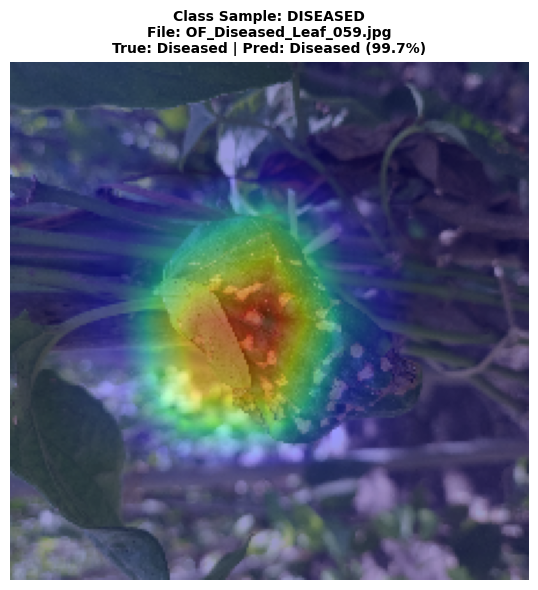

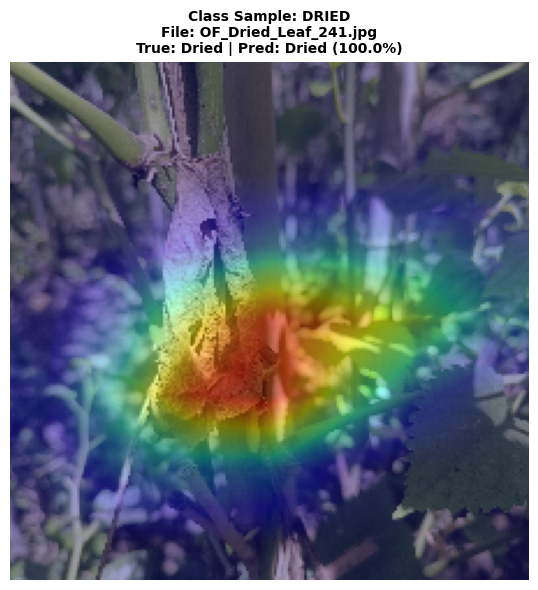

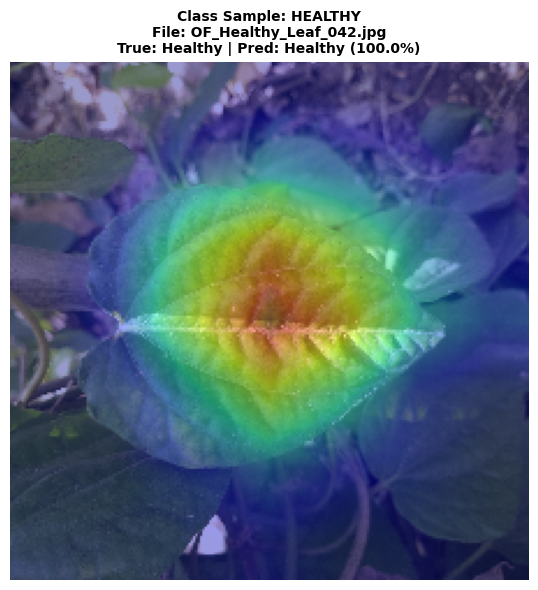

In [7]:
# ==============================================================================
# STEP 7: ON-FIELD MODEL EVALUATION & EXHAUSTIVE TEST-SET GRAD-CAM AUDIT
# ==============================================================================

# ------------------------------------------
# 7.1 ON-FIELD TRAINING CURVES
# ------------------------------------------

print("\n=======================================================")
print(" 📊 GENERATING ON-FIELD TRAINING HISTORY CURVES")
print("=======================================================\n")

# Reuse training curve function from Step 5 to plot OF history
plot_training_curves(history_of)


# ------------------------------------------
# 7.2 QUANTITATIVE EVALUATION & METRICS REPORT
# ------------------------------------------

# Run test set evaluation and display confusion matrix for On-Field model
evaluate_model_performance(of_model, of_test_gen)


# ------------------------------------------
# 7.3 SAMPLE ATTENTION OVERLAYS (1 PER CLASS: Healthy, Diseased, Dried)
# ------------------------------------------

def display_single_overlay_per_class(model, test_df, layer_name="top_conv"):
    """
    Finds the first sample of each target class ('Healthy', 'Diseased', 'Dried') 
    in test_df and displays a separate, standalone Attention Overlay image for each.
    """
    print(f"\n=======================================================")
    print(f" 🔍 DISPLAYING SAMPLE ATTENTION OVERLAYS (1 PER CLASS)")
    print(f"=======================================================\n")

    # Loop over each defined target category in exact order
    for target_class in CLASSES:
        # Filter test DataFrame to extract the first image path belonging to target_class
        sample_rows = test_df[test_df['label'] == target_class]
        
        if len(sample_rows) == 0:
            print(f"⚠️ No samples found for class: {target_class}")
            continue
            
        sample_row = sample_rows.iloc[0]
        filepath = sample_row['filepath']
        true_label = sample_row['label']
        
        # Extract original file name from disk path
        original_filename = os.path.basename(filepath)
        
        # Load and preprocess image
        img = tf.keras.preprocessing.image.load_img(filepath, target_size=(IMG_HEIGHT, IMG_WIDTH))
        img_array = tf.keras.preprocessing.image.img_to_array(img)
        preprocessed_img = tf.keras.applications.efficientnet.preprocess_input(img_array.copy())
        preprocessed_batch = np.expand_dims(preprocessed_img, axis=0)
        
        # Predict class
        preds = model.predict(preprocessed_batch, verbose=0)
        pred_idx = np.argmax(preds[0])
        pred_label = CLASSES[pred_idx]
        confidence = preds[0][pred_idx] * 100
        
        # Generate Grad-CAM heatmap using function defined in Step 5
        heatmap = make_gradcam_heatmap(preprocessed_batch, model, layer_name, pred_idx)
        
        # Normalize raw image pixels to [0, 1] range for Matplotlib rendering
        raw_img = img_array / 255.0
        
        # Resize heatmap tensor to 224x224
        heatmap_resized = tf.image.resize(
            np.expand_dims(heatmap, axis=-1), (IMG_HEIGHT, IMG_WIDTH)
        ).numpy().squeeze()

        # ------------------------------------------
        # RENDER SEPARATE STANDALONE OVERLAY FIGURE
        # ------------------------------------------
        plt.figure(figsize=(6, 6))
        
        # Plot base original image
        plt.imshow(raw_img)
        
        # Plot overlaid heatmap with 40% transparency
        plt.imshow(heatmap_resized, cmap='jet', alpha=0.4)
        
        # Title displaying Target Category, Original Filename, True Label, and Prediction
        plt.title(
            f"Class Sample: {target_class.upper()}\nFile: {original_filename}\nTrue: {true_label} | Pred: {pred_label} ({confidence:.1f}%)", 
            fontsize=10, 
            fontweight='bold'
        )
        
        plt.axis('off')
        plt.tight_layout()
        plt.show()
        plt.close()  # Clear memory handle


# Run single overlay visual audit for On-Field test set
display_single_overlay_per_class(model=of_model, test_df=of_test_df, layer_name="top_conv")